# Stacked Hourglass — Face Alignment

**Объединённая версия:** архитектура и подготовка разметки из VS Code, обучение и выравнивание из Google Colab. Существующие исходные ноутбуки не изменены.

**Важно:** для повторного запуска на GPU сначала используйте секции 1–7. Подготовка CSV и ZIP на Windows сохранена как **справочное приложение** внизу — её нельзя запускать в Colab. Не используйте «Выполнить всё», если не намерены заново обучать 20 эпох и формировать архив.

**Имеющиеся результаты:** 9 979 изображений после проверки, лучшая эпоха 19, Test Loss ≈ 0.000078, предварительный NME ≈ 2.14%. Для повторной оценки достаточно загружать `best_hourglass.pth`, обучать заново не нужно.

## 1. Google Colab — GPU, Google Drive и исходный архив

In [ ]:
import torch

print("CUDA доступна:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("Видеокарта:", torch.cuda.get_device_name(0))

In [ ]:
from google.colab import drive

drive.mount("/content/drive")

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import cv2

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
import torch.optim as optim

In [ ]:
archives = list(
    Path("/content/drive/MyDrive").rglob("face_alignment_data.zip")
)

print("Найдено архивов:", len(archives))

for archive in archives:
    print(archive)

In [ ]:
from zipfile import ZipFile
from pathlib import Path

# Берём найденный архив
archive_path = archives[0]

# Папка, куда распакуем данные
DATA_DIR = Path("/content/face_alignment_data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Распаковываем
with ZipFile(archive_path, "r") as zip_file:
    zip_file.extractall(DATA_DIR)

print("Архив распакован!")
print("Папка:", DATA_DIR)

In [ ]:
IMAGES_DIR = DATA_DIR / "images"
splits_dir = DATA_DIR / "splits"

train_df = pd.read_csv(splits_dir / "train.csv")
val_df = pd.read_csv(splits_dir / "val.csv")
test_df = pd.read_csv(splits_dir / "test.csv")

print("Фотографий:", len(list(IMAGES_DIR.glob("*.jpg"))))
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

assert len(train_df) + len(val_df) + len(test_df) == 9979

print("Данные готовы!")

## 2. Архитектура и Dataset
Классы взяты из работающих ноутбуков. `LandmarkDataset` использует расширение bbox на 20%.

In [ ]:
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.skip = nn.Identity() if in_channels == out_channels else nn.Conv2d(in_channels, out_channels, 1)

        self.conv1 = nn.Conv2d(in_channels, out_channels // 2, 1)
        self.bn1 = nn.BatchNorm2d(out_channels // 2)
        self.conv2 = nn.Conv2d(out_channels // 2, out_channels // 2, 3, padding=1)
        self.bn2 = nn.BatchNorm2d(out_channels // 2)
        self.conv3 = nn.Conv2d(out_channels // 2, out_channels, 1)
        self.bn3 = nn.BatchNorm2d(out_channels)

        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        residual = self.skip(x)
        x = self.relu(self.bn1(self.conv1(x)))
        x = self.relu(self.bn2(self.conv2(x)))
        x = self.bn3(self.conv3(x))
        return self.relu(x + residual)

In [ ]:
class Hourglass(nn.Module):
    def __init__(self, depth, f, increase=0):
        super().__init__()

        self.depth = depth
        nf = f + increase

        self.up1 = ResidualBlock(f, f)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.low1 = ResidualBlock(f, nf)

        if depth > 1:
            self.low2 = Hourglass(depth - 1, nf, increase)
        else:
            self.low2 = ResidualBlock(nf, nf)

        self.low3 = ResidualBlock(nf, f)
        self.up2 = nn.Upsample(scale_factor=2, mode="nearest")

    def forward(self, x):
        up1 = self.up1(x)

        pool1 = self.pool1(x)
        low1 = self.low1(pool1)
        low2 = self.low2(low1)
        low3 = self.low3(low2)

        up2 = self.up2(low3)

        if up1.shape[-2:] != up2.shape[-2:]:
            up2 = F.interpolate(
                up2,
                size=up1.shape[-2:],
                mode="nearest"
            )

        return up1 + up2

In [ ]:
class Merge(nn.Module):
    def __init__(self, x_dim, y_dim):
        super().__init__()

        self.conv = nn.Conv2d(
            x_dim, y_dim,
            kernel_size=1,
            bias=False
        )
        self.bn = nn.BatchNorm2d(y_dim)

    def forward(self, x):
        return self.bn(self.conv(x))


class HeatmapLoss(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, pred, gt):
        return ((pred - gt) ** 2).mean()

In [ ]:
class StackedHourglass(nn.Module):
    def __init__(self, nstack=2, inp_dim=128, oup_dim=5, increase=0):
        super().__init__()

        self.nstack = nstack

        # Предобработка исходного RGB-изображения
        self.pre = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=7, stride=2, padding=3, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),

            ResidualBlock(64, 128),
            nn.MaxPool2d(kernel_size=2, stride=2),
            ResidualBlock(128, 128),
            ResidualBlock(128, inp_dim)
        )

        # Несколько Hourglass
        self.hgs = nn.ModuleList([
            Hourglass(depth=3, f=inp_dim, increase=increase)
            for _ in range(nstack)
        ])

        # Обработка признаков после каждого Hourglass
        self.features = nn.ModuleList([
            nn.Sequential(
                ResidualBlock(inp_dim, inp_dim),
                nn.Conv2d(inp_dim, inp_dim, kernel_size=1, bias=False),
                nn.BatchNorm2d(inp_dim),
                nn.ReLU(inplace=True)
            )
            for _ in range(nstack)
        ])

        # Предсказание пяти heatmaps
        self.outs = nn.ModuleList([
            nn.Conv2d(inp_dim, oup_dim, kernel_size=1)
            for _ in range(nstack)
        ])

        # Соединения между Hourglass
        self.merge_features = nn.ModuleList([
            Merge(inp_dim, inp_dim)
            for _ in range(nstack - 1)
        ])

        self.merge_preds = nn.ModuleList([
            Merge(oup_dim, inp_dim)
            for _ in range(nstack - 1)
        ])

        self.heatmap_loss = HeatmapLoss()

    def forward(self, x):
        x = self.pre(x)

        combined_hm_preds = []

        for i in range(self.nstack):
            hg = self.hgs[i](x)
            feature = self.features[i](hg)
            preds = self.outs[i](feature)

            combined_hm_preds.append(preds)

            if i < self.nstack - 1:
                x = (
                    x
                    + self.merge_preds[i](preds)
                    + self.merge_features[i](feature)
                )

        return torch.stack(combined_hm_preds, dim=1)

    def calc_loss(self, outputs, targets):
        total_loss = 0.0
        nstacks = outputs.size(1)

        for i in range(nstacks):
            pred = outputs[:, i]
            total_loss += self.heatmap_loss(pred, targets)

        return total_loss / nstacks

In [ ]:
class LandmarkDataset(Dataset):
    def __init__(self, dataframe, images_dir):
        self.df = dataframe.reset_index(drop=True)
        self.images_dir = Path(images_dir)

        self.landmark_columns = [
            "lefteye_x", "lefteye_y",
            "righteye_x", "righteye_y",
            "nose_x", "nose_y",
            "leftmouth_x", "leftmouth_y",
            "rightmouth_x", "rightmouth_y"
        ]

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        #  Открываем фотографию
        path = self.images_dir / row["image_id"]
        image = cv2.imread(str(path))

        if image is None:
            raise FileNotFoundError(path)

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        #  Получаем bbox
        x, y, w, h = row[
            ["x_1", "y_1", "width", "height"]
        ].to_numpy(dtype=np.float32).astype(int)

        # Получаем пять landmarks
        landmarks = row[
            self.landmark_columns
        ].to_numpy(dtype=np.float32).reshape(5, 2)

        # Обрезаем лицо
        img_h, img_w = image.shape[:2]

        margin = 0.2

        pad_x = int(w * margin)
        pad_y = int(h * margin)

        x1 = max(0, x - pad_x)
        y1 = max(0, y - pad_y)
        x2 = min(img_w, x + w + pad_x)
        y2 = min(img_h, y + h + pad_y)

        if x2 <= x1 or y2 <= y1:
            raise ValueError(f"Некорректный bbox: {path.name}")

        image = image[y1:y2, x1:x2].copy()

        landmarks[:, 0] -= x1
        landmarks[:, 1] -= y1

        #  Изменяем размер до 256x256
        old_h, old_w = image.shape[:2]

        image = cv2.resize(image, (256, 256))

        landmarks[:, 0] *= 256 / old_w
        landmarks[:, 1] *= 256 / old_h

        #  Масштабируем точки для heatmaps 64x64
        hm_landmarks = landmarks * (64 / 256)

        yy, xx = np.mgrid[0:64, 0:64]

        heatmaps = []

        for px, py in hm_landmarks:
            heatmap = np.exp(
                -((xx - px)**2 + (yy - py)**2) / (2 * 2**2)
            )

            heatmaps.append(heatmap)

        heatmaps = np.stack(heatmaps).astype(np.float32)

        #  Переводим изображение в тензор PyTorch
        image = image.astype(np.float32) / 255.0

        image = torch.from_numpy(
            image.transpose(2, 0, 1).copy()
        )

        heatmaps = torch.from_numpy(heatmaps)

        return image, heatmaps

## 3. DataLoader и модель на GPU

In [ ]:
from torch.utils.data import DataLoader

train_dataset = LandmarkDataset(train_df, IMAGES_DIR)
val_dataset = LandmarkDataset(val_df, IMAGES_DIR)
test_dataset = LandmarkDataset(test_df, IMAGES_DIR)

train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

assert device.type == "cuda", "GPU не подключён"

model = StackedHourglass(
    nstack=2,
    inp_dim=128,
    oup_dim=5,
    increase=0
).to(device)

print("Устройство:", device)
print("GPU:", torch.cuda.get_device_name(0))

In [ ]:
images, targets = next(iter(train_loader))

images = images.to(device)
targets = targets.to(device)

model.eval()

with torch.no_grad():
    outputs = model(images)
    loss = model.calc_loss(outputs, targets)

print("Images:", images.shape)
print("Targets:", targets.shape)
print("Outputs:", outputs.shape)
print("Loss:", loss.item())

assert outputs.shape == (8, 2, 5, 64, 64)

print("Модель готова к обучению!")

## 4. Обучение (только если требуется повторный запуск)
**Пропустите две следующие ячейки при работе с уже обученной моделью.** Ранее завершены 20 эпох, лучший checkpoint сохранён на Google Drive. При повторном обучении он может быть перезаписан.

In [ ]:
# Оптимизатор
optimizer = optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-5
)

# Автоматическое уменьшение learning rate
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=7,
    min_lr=1e-6
)

# Папка для сохранения обученной модели
checkpoint_dir = archives[0].parent / "checkpoints"
checkpoint_dir.mkdir(parents=True, exist_ok=True)

print("Оптимизатор:", type(optimizer).__name__)
print("Папка для весов:", checkpoint_dir)

In [ ]:
from tqdm.auto import tqdm

num_epochs = 20
best_val_loss = float("inf")

for epoch in range(num_epochs):

    # ===== ОБУЧЕНИЕ =====
    model.train()

    train_loss_sum = 0.0

    for images, targets in tqdm(
        train_loader,
        desc=f"Эпоха {epoch + 1}/{num_epochs} — Train"
    ):
        images = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        # Обнуляем градиенты
        optimizer.zero_grad()

        # Прямой проход
        outputs = model(images)

        # Вычисляем ошибку
        loss = model.calc_loss(outputs, targets)

        # Вычисляем градиенты
        loss.backward()

        # Обновляем веса модели
        optimizer.step()

        train_loss_sum += loss.item() * images.size(0)

    train_loss = train_loss_sum / len(train_dataset)

    # ===== ВАЛИДАЦИЯ =====
    model.eval()

    val_loss_sum = 0.0

    with torch.no_grad():
        for images, targets in tqdm(
            val_loader,
            desc=f"Эпоха {epoch + 1}/{num_epochs} — Val"
        ):
            images = images.to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True)

            outputs = model(images)
            loss = model.calc_loss(outputs, targets)

            val_loss_sum += loss.item() * images.size(0)

    val_loss = val_loss_sum / len(val_dataset)

    # Обновляем learning rate
    scheduler.step(val_loss)

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Train Loss: {train_loss:.6f} | "
        f"Val Loss: {val_loss:.6f} | "
        f"LR: {optimizer.param_groups[0]['lr']:.6f}"
    )

    # ===== СОХРАНЕНИЕ ЛУЧШЕЙ МОДЕЛИ =====
    if val_loss < best_val_loss:
        best_val_loss = val_loss

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "scheduler_state_dict": scheduler.state_dict(),
                "best_val_loss": best_val_loss,
            },
            checkpoint_dir / "best_hourglass.pth"
        )

        print("Лучшая модель сохранена!")

Эпоха 1/20 — Train:   0%|          | 0/998 [00:00<?, ?it/s]

Эпоха 1/20 — Val:   0%|          | 0/125 [00:00<?, ?it/s]

Epoch 1/20 | Train Loss: 0.001797 | Val Loss: 0.000359 | LR: 0.001000
Лучшая модель сохранена!


Эпоха 2/20 — Train:   0%|          | 0/998 [00:00<?, ?it/s]

Эпоха 2/20 — Val:   0%|          | 0/125 [00:00<?, ?it/s]

Epoch 2/20 | Train Loss: 0.000238 | Val Loss: 0.000215 | LR: 0.001000
Лучшая модель сохранена!


... (58 outputs left out)

Epoch 19/20 | Train Loss: 0.000048 | Val Loss: 0.000078 | LR: 0.001000
Лучшая модель сохранена!


Эпоха 20/20 — Train:   0%|          | 0/998 [00:00<?, ?it/s]

Эпоха 20/20 — Val:   0%|          | 0/125 [00:00<?, ?it/s]

Epoch 20/20 | Train Loss: 0.000044 | Val Loss: 0.000091 | LR: 0.001000


## 5. Загрузка сохранённого checkpoint и оценка на test
Эта часть используется без повторного обучения. Переменная `checkpoint_dir` определяется ниже самостоятельно, даже если раздел обучения пропущен.

In [ ]:
checkpoint_dir = archives[0].parent / "checkpoints"
assert (checkpoint_dir / "best_hourglass.pth").exists(), "Не найден best_hourglass.pth на Google Drive"

In [ ]:
checkpoint_path = checkpoint_dir / "best_hourglass.pth"

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Загружена эпоха:", checkpoint["epoch"])
print("Лучший Val Loss:", checkpoint["best_val_loss"])

In [ ]:
test_loss_sum = 0.0

with torch.no_grad():
    for images, targets in test_loader:
        images = images.to(device)
        targets = targets.to(device)

        outputs = model(images)
        loss = model.calc_loss(outputs, targets)

        test_loss_sum += loss.item() * images.size(0)

test_loss = test_loss_sum / len(test_dataset)

print(f"Test Loss: {test_loss:.6f}")

Test Loss: 0.000078


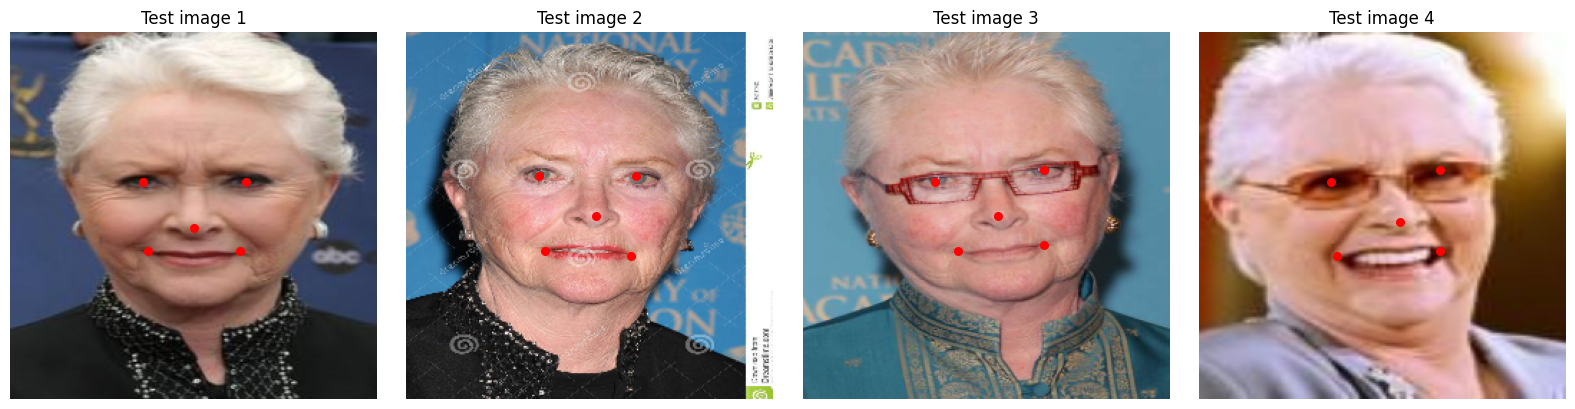

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch

# Берём первые 4 фотографии тестовой выборки
images, targets = next(iter(test_loader))

images = images[:4].to(device)

# Модель работает в режиме предсказания
model.eval()

with torch.no_grad():
    outputs = model(images)

# Берём heatmaps последнего Hourglass
pred_heatmaps = outputs[:, -1]

# Переносим результаты на CPU
images = images.cpu()
pred_heatmaps = pred_heatmaps.cpu()

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for i in range(4):
    # (3, 256, 256) -> (256, 256, 3)
    image = images[i].permute(1, 2, 0).numpy()

    axes[i].imshow(image)

    # Для каждой из 5 ключевых точек
    for j in range(5):
        heatmap = pred_heatmaps[i, j].numpy()

        # Ищем пиксель с максимальной интенсивностью
        y, x = np.unravel_index(
            np.argmax(heatmap),
            heatmap.shape
        )

        # Переводим координаты из 64x64 в 256x256
        x = x * 4
        y = y * 4

        axes[i].scatter(x, y, c="red", s=30)

    axes[i].axis("off")
    axes[i].set_title(f"Test image {i + 1}")

plt.tight_layout()
plt.show()

In [ ]:
def heatmaps_to_landmarks(heatmaps):
    """
    heatmaps: (B, 5, 64, 64)
    результат: (B, 5, 2), координаты в 256x256
    """
    batch_size, num_points, h, w = heatmaps.shape

    indices = heatmaps.reshape(batch_size, num_points, -1).argmax(dim=2)

    x = (indices % w).float() * (256 / w)
    y = (indices // w).float() * (256 / h)

    return torch.stack([x, y], dim=-1)


def calculate_nme(pred_landmarks, gt_landmarks):
    distances = torch.linalg.vector_norm(
        pred_landmarks - gt_landmarks,
        dim=2
    )

    interocular = torch.linalg.vector_norm(
        gt_landmarks[:, 0] - gt_landmarks[:, 1],
        dim=1
    ).clamp(min=1e-6)

    return (distances.mean(dim=1) / interocular).mean()

In [ ]:
model.eval()

total_nme = 0.0
total_images = 0

with torch.no_grad():
    for images, targets in test_loader:
        images = images.to(device)
        targets = targets.to(device)

        outputs = model(images)

        # Последний Hourglass
        pred_heatmaps = outputs[:, -1]

        pred_landmarks = heatmaps_to_landmarks(pred_heatmaps)
        gt_landmarks = heatmaps_to_landmarks(targets)

        batch_nme = calculate_nme(pred_landmarks, gt_landmarks)

        total_nme += batch_nme.item() * images.size(0)
        total_images += images.size(0)

test_nme = total_nme / total_images

print(f"Test NME: {test_nme:.4f}")
print(f"Test NME (%): {test_nme * 100:.2f}%")

Test NME: 0.0214
Test NME (%): 2.14%


## 6. Face Alignment по пяти точкам
Сначала задаём эталонные координаты, потом функцию. Пяти-точечное преобразование — фактически использованный вариант из Colab. Это не идентично трёх-точечному варианту из ноутбука разработчика.

In [ ]:
STANDARD_LANDMARKS = np.array([
    [38.2946, 51.6963],  # Левый глаз
    [73.5318, 51.5014],  # Правый глаз
    [56.0252, 71.7366],  # Нос
    [41.5493, 92.3655],  # Левый угол рта
    [70.7291, 92.2041]   # Правый угол рта
], dtype=np.float32)

In [ ]:
def align_face_5points(image, landmarks, output_size=112):
    landmarks = np.asarray(landmarks, dtype=np.float32)

    reference = STANDARD_LANDMARKS.copy()
    reference *= output_size / 112

    # Подбираем преобразование по всем пяти точкам
    matrix, _ = cv2.estimateAffinePartial2D(
        landmarks,
        reference,
        method=cv2.LMEDS
    )

    if matrix is None:
        raise ValueError("Не удалось выровнять лицо")

    aligned = cv2.warpAffine(
        image,
        matrix,
        (output_size, output_size),
        flags=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_REFLECT
    )

    return aligned

In [ ]:

# Берём фотографию из тестовой выборки
image, target = test_dataset[0]

input_tensor = image.unsqueeze(0).to(device)

model.eval()

with torch.no_grad():
    outputs = model(input_tensor)

# Heatmaps последнего Hourglass
heatmaps = outputs[:, -1]

# Получаем координаты landmarks
landmarks = heatmaps_to_landmarks(heatmaps)[0].cpu().numpy()

# Преобразуем тензор в RGB-изображение
image_np = (
    image.permute(1, 2, 0).numpy() * 255
).astype(np.uint8)

# Выравниваем лицо
aligned = align_face_5points(image_np, landmarks, output_size=112)

# Показываем результат
fig, axes = plt.subplots(1, 2, figsize=(9, 4))

axes[0].imshow(image_np)
axes[0].scatter(
    landmarks[:, 0],
    landmarks[:, 1],
    c="red",
    s=25
)
axes[0].set_title("До выравнивания")
axes[0].axis("off")

axes[1].imshow(aligned)
axes[1].set_title("После: 5 landmarks, 112×112")
axes[1].axis("off")

plt.tight_layout()
plt.show()

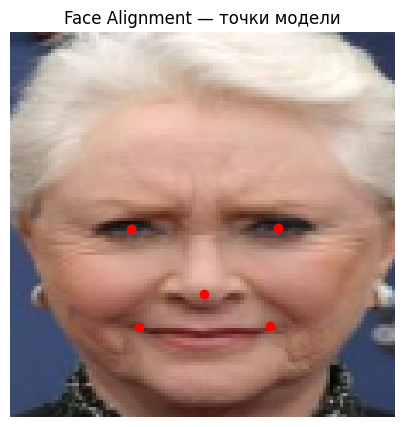

In [ ]:
# Выравниваем лицо
aligned = align_face_5points(
    image_np,
    landmarks,
    output_size=112
)

# Вычисляем то же преобразование для координат точек
matrix, _ = cv2.estimateAffinePartial2D(
    landmarks.astype(np.float32),
    STANDARD_LANDMARKS.astype(np.float32),
    method=cv2.LMEDS
)

# Переносим точки на выровненное изображение
transformed = cv2.transform(
    landmarks.reshape(1, 5, 2).astype(np.float32),
    matrix
)[0]

plt.figure(figsize=(5, 5))

plt.imshow(aligned)

plt.scatter(
    transformed[:, 0],
    transformed[:, 1],
    c="red",
    s=35
)

plt.title("Face Alignment — точки модели")
plt.axis("off")
plt.show()

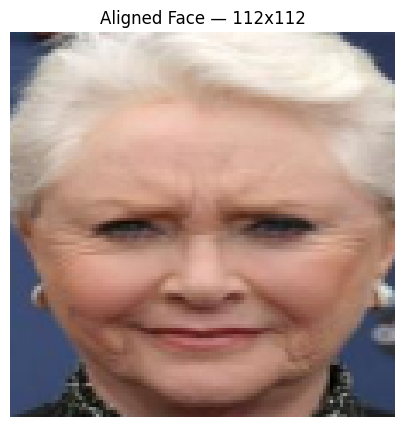

In [ ]:
plt.figure(figsize=(5, 5))

plt.imshow(aligned)
plt.title("Aligned Face — 112x112")
plt.axis("off")

plt.show()

## 7. Массовое выравнивание и сохранение архива
Выполняйте только для повторной генерации файлов. Выровненные JPG сохраняются в `/content/aligned_faces`, а архив — рядом с исходным ZIP на Google Drive.

In [ ]:
# Куда сохраняем выровненные фотографии
ALIGNED_DIR = Path("/content/aligned_faces")
ALIGNED_DIR.mkdir(parents=True, exist_ok=True)

# Загружаем лучшую обученную модель
checkpoint = torch.load(
    checkpoint_dir / "best_hourglass.pth",
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

print("Загружена эпоха:", checkpoint["epoch"])
print("Папка для результатов:", ALIGNED_DIR)

In [ ]:
from torch.utils.data import DataLoader

# Объединяем фотографии всех трёх выборок.
# Само разделение train/val/test при этом сохраняем в CSV.
all_df = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True
)

alignment_dataset = LandmarkDataset(all_df, IMAGES_DIR)

alignment_loader = DataLoader(
    alignment_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

saved_count = 0
failed_images = []

model.eval()

with torch.no_grad():
    for batch_idx, (images, _) in enumerate(
        tqdm(alignment_loader, desc="Face Alignment")
    ):
        # Предсказания на GPU
        outputs = model(images.to(device))

        # Последний Hourglass -> координаты 5 точек
        predicted_landmarks = heatmaps_to_landmarks(
            outputs[:, -1]
        ).cpu().numpy()

        # Возвращаем изображения в обычный RGB-формат
        images_np = (
            images.permute(0, 2, 3, 1).numpy() * 255
        ).clip(0, 255).astype(np.uint8)

        # Обрабатываем каждую фотографию внутри батча
        for j in range(len(images_np)):
            index = batch_idx * alignment_loader.batch_size + j
            filename = str(all_df.iloc[index]["image_id"])

            try:
                aligned = align_face_5points(
                    images_np[j],
                    predicted_landmarks[j],
                    output_size=112
                )

                # OpenCV сохраняет изображения в формате BGR
                aligned_bgr = cv2.cvtColor(
                    aligned,
                    cv2.COLOR_RGB2BGR
                )

                output_path = ALIGNED_DIR / filename

                success = cv2.imwrite(
                    str(output_path),
                    aligned_bgr
                )

                if not success:
                    raise RuntimeError("Не удалось сохранить JPG")

                saved_count += 1

            except (ValueError, cv2.error, RuntimeError) as error:
                failed_images.append((filename, str(error)))

print("Всего фотографий:", len(all_df))
print("Сохранено:", saved_count)
print("Ошибок:", len(failed_images))
print("Примеры ошибок:", failed_images[:5])

Face Alignment:   0%|          | 0/1248 [00:00<?, ?it/s]

Всего фотографий: 9979
Сохранено: 9979
Ошибок: 0
Примеры ошибок: []


Найдено JPG: 9979


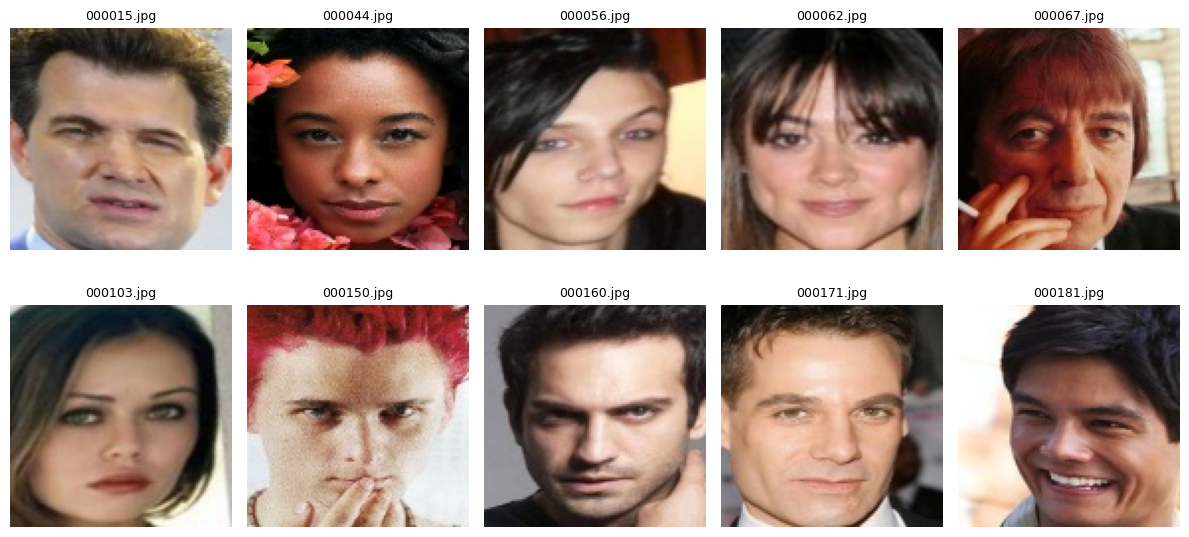

In [ ]:
saved_files = sorted(ALIGNED_DIR.glob("*.jpg"))

print("Найдено JPG:", len(saved_files))

assert len(saved_files) == len(all_df), (
    f"Ожидалось {len(all_df)}, найдено {len(saved_files)}"
)

fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for ax, path in zip(axes.flat, saved_files[:10]):
    image = cv2.imread(str(path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    assert image.shape == (112, 112, 3)

    ax.imshow(image)
    ax.set_title(path.name, fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

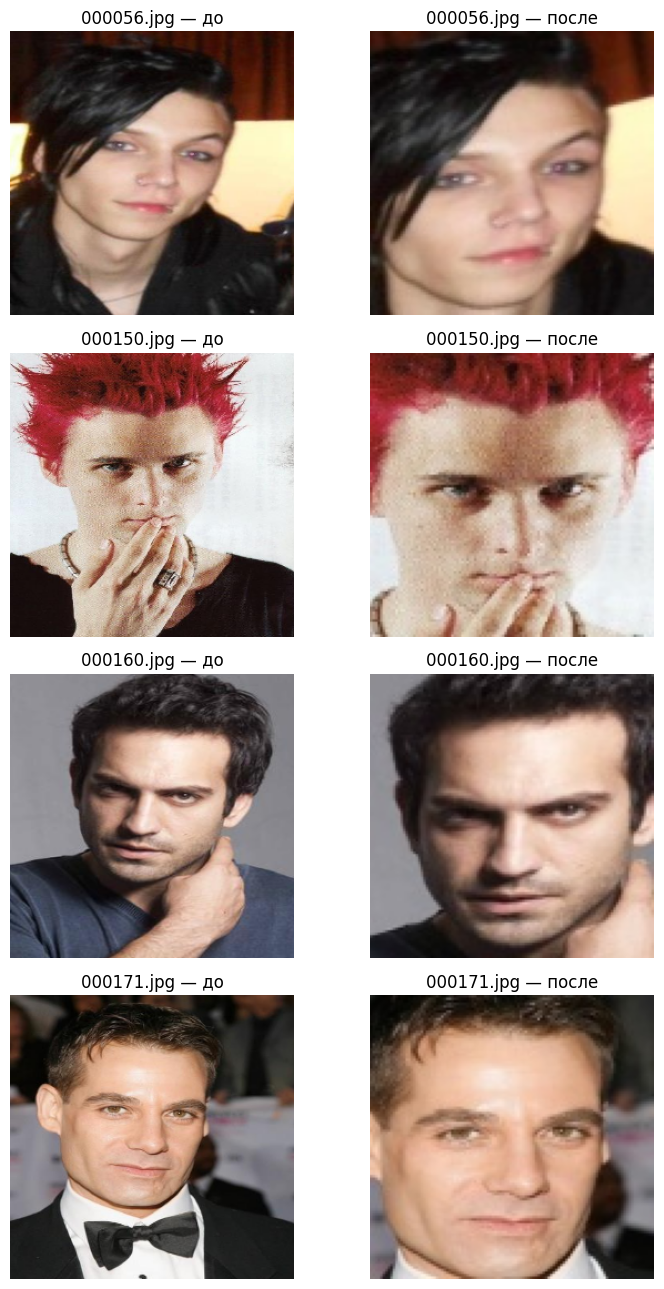

In [ ]:
import matplotlib.pyplot as plt
import cv2

# Фотографии, которые хотим проверить
filenames = [
    "000056.jpg",
    "000150.jpg",
    "000160.jpg",
    "000171.jpg"
]

fig, axes = plt.subplots(len(filenames), 2, figsize=(8, 13))

for i, filename in enumerate(filenames):

    # Исходное изображение после crop и resize
    row_idx = all_df.index[
        all_df["image_id"] == filename
    ][0]

    image_tensor, _ = alignment_dataset[row_idx]

    original = (
        image_tensor.permute(1, 2, 0).numpy() * 255
    ).astype("uint8")

    # Сохранённое выровненное изображение
    aligned = cv2.imread(str(ALIGNED_DIR / filename))
    aligned = cv2.cvtColor(aligned, cv2.COLOR_BGR2RGB)

    axes[i, 0].imshow(original)
    axes[i, 0].set_title(f"{filename} — до")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(aligned)
    axes[i, 1].set_title(f"{filename} — после")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from zipfile import ZipFile, ZIP_STORED

# Создаём архив рядом с исходным face_alignment_data.zip
output_zip = archives[0].parent / "aligned_faces_112.zip"

with ZipFile(output_zip, "w", compression=ZIP_STORED) as zip_file:

    # Выровненные фотографии
    for path in tqdm(saved_files, desc="Сохранение на Google Drive"):
        zip_file.write(
            path,
            arcname=f"images/{path.name}"
        )

    # Исходное разделение сохраняем вместе с фотографиями
    for filename in ["train.csv", "val.csv", "test.csv"]:
        zip_file.write(
            splits_dir / filename,
            arcname=f"splits/{filename}"
        )

print("Архив сохранён:", output_zip)
print("Размер, МБ:", round(output_zip.stat().st_size / 1024**2, 1))

Сохранение на Google Drive:   0%|          | 0/9979 [00:00<?, ?it/s]

Архив сохранён: /content/drive/MyDrive/face_recognition/aligned_faces_112.zip
Размер, МБ: 65.4


## Приложение A. Локальная подготовка в VS Code — история и код

**Не выполнять в Colab.** Следующие фрагменты сохранены из локального `02_hourglass_model.ipynb` как документирование этапа: выборка 500 людей, разбиение train/validation/test, контроль bbox и сохранение ZIP. Сам исходный ноутбук VS Code оставлен отдельным файлом, с исполняемыми ячейками. Здесь код приведён для полноты истории без изменения текущих переменных Colab.

### Локальные пути и исходная таблица

```python
# Находим корень проекта
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent


csv_path = PROJECT_ROOT / "data" / "processed" / "selected_celeba.csv"

selected_df = pd.read_csv(csv_path)


raw_dir = PROJECT_ROOT / "data" / "raw"
first_filename = selected_df.iloc[0]["image_id"]

matches = list(raw_dir.rglob(first_filename))

if not matches:
    raise FileNotFoundError(f"Не найдено изображение {first_filename}")

IMAGES_DIR = matches[0].parent

print("Фотографий:", len(selected_df))
print("Папка изображений:", IMAGES_DIR)
print("Количество людей:", selected_df["identity_id"].nunique())
```

### Локальная проверка Dataset

```python
dataset = LandmarkDataset(
    dataframe=selected_df,
    images_dir=IMAGES_DIR
)

print("Размер датасета:", len(dataset))

image, heatmaps = dataset[0]

print("Изображение:", image.shape)
print("Heatmaps:", heatmaps.shape)

assert image.shape == (3, 256, 256)
assert heatmaps.shape == (5, 64, 64)

```

### Разделение по identity_id (seed=42)

```python

person_ids = selected_df["identity_id"].unique()


rng = np.random.default_rng(42)
person_ids = rng.permutation(person_ids)


train_ids = person_ids[:400]
val_ids = person_ids[400:450]
test_ids = person_ids[450:500]


train_df = selected_df[
    selected_df["identity_id"].isin(train_ids)
].copy()

val_df = selected_df[
    selected_df["identity_id"].isin(val_ids)
].copy()

test_df = selected_df[
    selected_df["identity_id"].isin(test_ids)
].copy()

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))



```

### Первый локальный DataLoader

```python
train_dataset = LandmarkDataset(train_df, IMAGES_DIR)
val_dataset = LandmarkDataset(val_df, IMAGES_DIR)
test_dataset = LandmarkDataset(test_df, IMAGES_DIR)

train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

images, targets = next(iter(train_loader))

print("Images:", images.shape)
print("Heatmaps:", targets.shape)
```

### Первое сохранение разбиения

```python
splits_dir = PROJECT_ROOT / "data" / "processed" / "splits"
splits_dir.mkdir(parents=True, exist_ok=True)

train_df.to_csv(splits_dir / "train.csv", index=False)
val_df.to_csv(splits_dir / "val.csv", index=False)
test_df.to_csv(splits_dir / "test.csv", index=False)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("Файлы сохранены в:", splits_dir)
```

### Контроль без margin

```python
# Проверяем координаты относительно bounding box
x1 = selected_df["x_1"].clip(lower=0)
y1 = selected_df["y_1"].clip(lower=0)

x2 = selected_df["x_1"] + selected_df["width"]
y2 = selected_df["y_1"] + selected_df["height"]

landmark_names = [
    "lefteye", "righteye", "nose",
    "leftmouth", "rightmouth"
]

valid = pd.Series(True, index=selected_df.index)

for name in landmark_names:
    px = selected_df[f"{name}_x"]
    py = selected_df[f"{name}_y"]

    valid &= (
        (px >= x1) & (px < x2) &
        (py >= y1) & (py < y2)
    )

print("Всего фотографий:", len(selected_df))
print("Все 5 точек внутри bbox:", valid.sum())
print("Есть точки вне bbox:", (~valid).sum())
```

### Функция crop с margin

```python
def crop_face_with_margin(image, bbox, landmarks, margin=0.2):
    x, y, w, h = map(int, bbox)

    img_h, img_w = image.shape[:2]

    # Добавляем 20% ширины и высоты с каждой стороны
    pad_x = int(w * margin)
    pad_y = int(h * margin)

    x1 = max(0, x - pad_x)
    y1 = max(0, y - pad_y)
    x2 = min(img_w, x + w + pad_x)
    y2 = min(img_h, y + h + pad_y)

    if x2 <= x1 or y2 <= y1:
        raise ValueError("Некорректный bounding box")

    cropped = image[y1:y2, x1:x2].copy()

    new_landmarks = landmarks.copy().astype(np.float32)
    new_landmarks[:, 0] -= x1
    new_landmarks[:, 1] -= y1

    return cropped, new_landmarks
```

### Контроль с margin

```python
# Проверяем координаты относительно расширенных bbox
margin = 0.2

x1 = (selected_df["x_1"] -
      selected_df["width"] * margin).clip(lower=0)

y1 = (selected_df["y_1"] -
      selected_df["height"] * margin).clip(lower=0)

x2 = selected_df["x_1"] + selected_df["width"] * (1 + margin)
y2 = selected_df["y_1"] + selected_df["height"] * (1 + margin)

valid_with_margin = pd.Series(True, index=selected_df.index)

for name in landmark_names:
    px = selected_df[f"{name}_x"]
    py = selected_df[f"{name}_y"]

    valid_with_margin &= (
        (px >= x1) & (px < x2) &
        (py >= y1) & (py < y2)
    )

print("Все точки внутри расширенного bbox:", valid_with_margin.sum())
print("Остались проблемные:", (~valid_with_margin).sum())
```

### Проверка JPG и фактических границ

```python
from tqdm.auto import tqdm

landmark_columns = [
    "lefteye_x", "lefteye_y",
    "righteye_x", "righteye_y",
    "nose_x", "nose_y",
    "leftmouth_x", "leftmouth_y",
    "rightmouth_x", "rightmouth_y"
]

valid_indices = []
problem_images = []

for idx, row in tqdm(selected_df.iterrows(), total=len(selected_df)):
    image_path = IMAGES_DIR / row["image_id"]
    image = cv2.imread(str(image_path))

    if image is None:
        problem_images.append((row["image_id"], "Файл не читается"))
        continue

    img_h, img_w = image.shape[:2]

    x, y, w, h = map(int, row[["x_1", "y_1", "width", "height"]])

    pad_x = int(w * 0.2)
    pad_y = int(h * 0.2)

    x1 = max(0, x - pad_x)
    y1 = max(0, y - pad_y)
    x2 = min(img_w, x + w + pad_x)
    y2 = min(img_h, y + h + pad_y)

    if x2 <= x1 or y2 <= y1:
        problem_images.append((row["image_id"], "Некорректный bbox"))
        continue

    landmarks = row[landmark_columns].to_numpy(
        dtype=np.float32
    ).reshape(5, 2)

    inside = (
        (landmarks[:, 0] >= x1) &
        (landmarks[:, 0] < x2) &
        (landmarks[:, 1] >= y1) &
        (landmarks[:, 1] < y2)
    ).all()

    if inside:
        valid_indices.append(idx)
    else:
        problem_images.append((row["image_id"], "Точка вне обрезки"))

print("Корректных изображений:", len(valid_indices))
print("Проблемных изображений:", len(problem_images))
print("Примеры проблем:", problem_images[:5])
```

### Исключение 21 файла и финальные CSV

```python
# Сохраняем только фотографии, прошедшие проверку
clean_df = selected_df.loc[valid_indices].copy()

# Сохраняем отдельный список исключённых фотографий
bad_df = selected_df.drop(index=valid_indices).copy()

# Используем те же ID людей, что выбрали раньше
train_df = clean_df[
    clean_df["identity_id"].isin(train_ids)
].copy()

val_df = clean_df[
    clean_df["identity_id"].isin(val_ids)
].copy()

test_df = clean_df[
    clean_df["identity_id"].isin(test_ids)
].copy()

# Сохраняем обновлённое разделение
splits_dir = PROJECT_ROOT / "data" / "processed" / "splits"
splits_dir.mkdir(parents=True, exist_ok=True)

train_df.to_csv(splits_dir / "train.csv", index=False)
val_df.to_csv(splits_dir / "val.csv", index=False)
test_df.to_csv(splits_dir / "test.csv", index=False)

bad_df.to_csv(splits_dir / "excluded.csv", index=False)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("Исключено:", len(bad_df))

assert len(train_df) + len(val_df) + len(test_df) == 9979
assert len(bad_df) == 21
```

### Создание face_alignment_data.zip

```python
from zipfile import ZipFile, ZIP_STORED
from pathlib import Path

archive_path = PROJECT_ROOT / "face_alignment_data.zip"

with ZipFile(archive_path, "w", compression=ZIP_STORED) as archive:
    # Упаковываем только проверенные фотографии
    for filename in clean_df["image_id"]:
        source = IMAGES_DIR / filename

        if not source.is_file():
            raise FileNotFoundError(source)

        archive.write(source, arcname=f"images/{filename}")

    # Упаковываем разделение датасета
    for filename in ["train.csv", "val.csv", "test.csv"]:
        source = splits_dir / filename
        archive.write(source, arcname=f"splits/{filename}")

print("Архив создан:", archive_path)
print("Размер, ГБ:", round(archive_path.stat().st_size / 1024**3, 2))
```